Mean Absolute Error (MAE): 9218.749603911872
Mean Squared Error (MSE): 243563883.94518128
Root Mean Squared Error (RMSE): 15606.53337372465
R² Score: 0.827871358317543


c:\Users\kimho\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


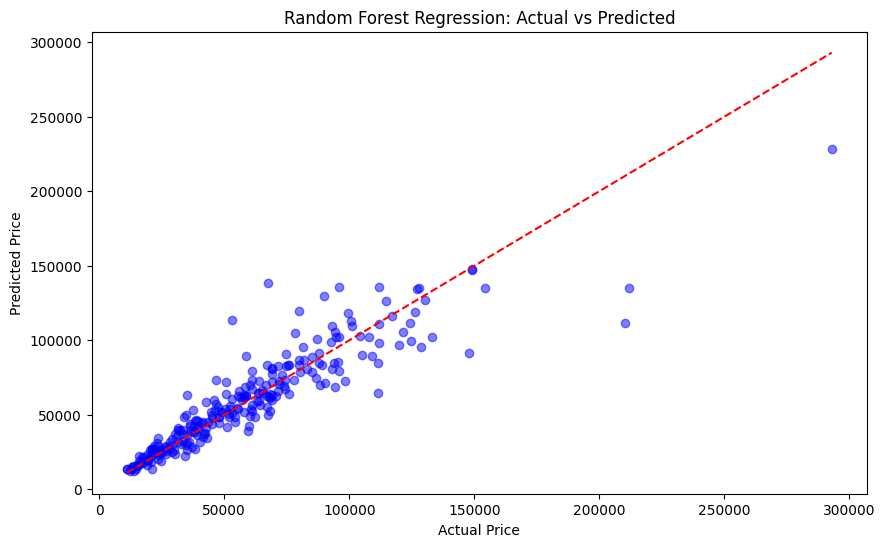

['trained_model_pipeline.pkl']

In [2]:
# Import necessary libraries
import numpy as np
import pandas as pd
import joblib
import os
import requests
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from dotenv import load_dotenv

# Load environment variables from .env file
load_dotenv()

# Load data for model building (example: laptopData.csv)
model_data_path = "../data/laptopData_table_cleaned.csv"  # Adjust the path to your dataset
if os.path.exists(model_data_path):
    df_model = pd.read_csv(model_data_path)
    
    # Display the dataset used for Random Forest Regression
    df_model.head()

    # Select features and target variable
    X = df_model.drop(columns=['Price'])  # Features (excluding the target)
    y = df_model['Price']  # Target variable

    # Define the numerical and categorical features for preprocessing
    numerical_features = ['Inches', 'Ram', 'Weight', 'Screen_Width', 'Screen_Height', 'ppi', 'CPU_Speed', 'SSD', 'HDD', 'Flash', 'Hybrid']
    numerical_transformer = StandardScaler()

    categorical_features = ['Company', 'TypeName', 'OpSys', 'Gpu_Brand', 'OS']
    categorical_transformer = OneHotEncoder(handle_unknown='ignore')

    # Combine the transformers in a column transformer
    preprocessor = ColumnTransformer(
        transformers=[ 
            ('num', numerical_transformer, numerical_features),
            ('cat', categorical_transformer, categorical_features)
        ])

    # Split data into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Create the pipeline with preprocessing and model
    pipeline = Pipeline(steps=[ 
        ('preprocessor', preprocessor), 
        ('model', RandomForestRegressor(n_estimators=100, random_state=42)) 
    ])

    # Train the model
    pipeline.fit(X_train, y_train)

    # Predict on the test set
    y_pred = pipeline.predict(X_test)

    # Evaluate model performance
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)  # Calculate RMSE separately using numpy
    r2 = r2_score(y_test, y_pred)
    # Display evaluation metrics
    print(f"Mean Absolute Error (MAE): {mae}")
    print(f"Mean Squared Error (MSE): {mse}")
    print(f"Root Mean Squared Error (RMSE): {rmse}")
    print(f"R² Score: {r2}")

    # Visualize predictions vs actual values
    plt.figure(figsize=(10, 6))
    plt.scatter(y_test, y_pred, color='blue', alpha=0.5)
    plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='--')
    plt.title("Random Forest Regression: Actual vs Predicted")
    plt.xlabel("Actual Price")
    plt.ylabel("Predicted Price")
    plt.show()

# After training the model pipeline, save it to a file
joblib.dump(pipeline, "trained_model_pipeline.pkl")
